# Practical 9: XOR Gate with Perceptron Learning Algorithm

A single-layer perceptron cannot solve XOR because XOR is not linearly separable. This notebook first demonstrates the single-layer limitation, then implements and trains a small multilayer network with backpropagation using only NumPy arithmetic and explicit loops (plus Pandas/Matplotlib for display and plotting). No built-in ML, neural-network, or perceptron library is used.

## XOR truth table

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({"x1": [0, 0, 1, 1], "x2": [0, 1, 0, 1], "target": [0, 1, 1, 0]})
display(data)
X = data[["x1", "x2"]].to_numpy(dtype=float)
y = data["target"].to_numpy(dtype=int)

def step(value):
    return 1 if value >= 0 else 0

def train_single_perceptron(X, y, learning_rate=0.1, max_epochs=100):
    weights = np.zeros(X.shape[1], dtype=float)
    bias = 0.0
    for _ in range(max_epochs):
        for inputs, target in zip(X, y):
            prediction = step(np.dot(inputs, weights) + bias)
            update = learning_rate * (target - prediction)
            weights += update * inputs
            bias += update
    return weights, bias

single_weights, single_bias = train_single_perceptron(X, y)
single_predictions = np.array([step(np.dot(row, single_weights) + single_bias) for row in X])
print("Single-layer weights:", single_weights, "bias:", single_bias)
display(pd.DataFrame({"x1": X[:, 0].astype(int), "x2": X[:, 1].astype(int),
                      "expected": y, "single_layer_prediction": single_predictions}))
print("A single linear decision boundary cannot classify XOR correctly.")

,x1,x2,target
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


Single-layer weights: [-0.1  0. ] bias: 0.0


,x1,x2,expected,single_layer_prediction
0,0,0,0,1
1,0,1,1,1
2,1,0,1,0
3,1,1,0,0


A single linear decision boundary cannot classify XOR correctly.


## Manually train a 2-2-1 network with backpropagation

The network has two input units, two sigmoid hidden units, and one sigmoid output. Backpropagation computes gradients from the output error and updates each weight and bias.

In [3]:
def sigmoid(z):
    z = np.clip(z, -40, 40)  # numerical stability
    return 1.0 / (1.0 + np.exp(-z))

rng = np.random.default_rng(42)
W1 = rng.normal(0, 0.8, size=(2, 2))  # input to hidden
b1 = np.zeros(2)
W2 = rng.normal(0, 0.8, size=(2, 1))  # hidden to output
b2 = np.zeros(1)
y_column = y.reshape(-1, 1).astype(float)
learning_rate = 1.0

for epoch in range(20000):
    # Forward pass
    hidden = sigmoid(X @ W1 + b1)
    output = sigmoid(hidden @ W2 + b2)
    # Backward pass for mean squared error
    output_delta = (output - y_column) * output * (1 - output) / len(X)
    hidden_delta = (output_delta @ W2.T) * hidden * (1 - hidden)
    grad_W2 = hidden.T @ output_delta
    grad_b2 = output_delta.sum(axis=0)
    grad_W1 = X.T @ hidden_delta
    grad_b1 = hidden_delta.sum(axis=0)
    # Gradient descent update
    W2 -= learning_rate * grad_W2
    b2 -= learning_rate * grad_b2
    W1 -= learning_rate * grad_W1
    b1 -= learning_rate * grad_b1

hidden = sigmoid(X @ W1 + b1)
probabilities = sigmoid(hidden @ W2 + b2).ravel()
multilayer_predictions = (probabilities >= 0.5).astype(int)
results = data.copy()
results["network_probability"] = probabilities
results["network_prediction"] = multilayer_predictions
display(results)
print("Learned all XOR cases:", np.array_equal(multilayer_predictions, y))

,x1,x2,target,network_probability,network_prediction
0,0,0,0,0.022481,0
1,0,1,1,0.974653,1
2,1,0,1,0.974850,1
3,1,1,0,0.020384,0


Learned all XOR cases: True


## Plot XOR outputs

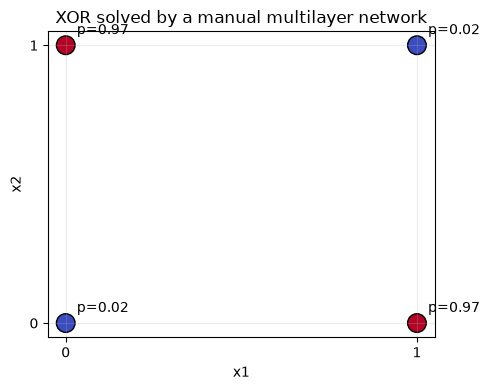

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=180, edgecolor="black")
for (x1, x2), probability in zip(X, probabilities):
    ax.annotate(f"p={probability:.2f}", (x1, x2), xytext=(8, 8), textcoords="offset points")
ax.set(xticks=[0, 1], yticks=[0, 1], xlabel="x1", ylabel="x2", title="XOR solved by a manual multilayer network")
ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

## Conclusion

The single threshold unit cannot represent XOR, while the hidden layer creates a nonlinear decision function that does. The entire implementation is inside this notebook and runs without the dataset CSV or shared script.